In [ ]:
import sys
!{sys.executable} -m pip install ucimlrepo

In [2]:
# Import necessary libraries for the start
import pandas as pd
import numpy as np

# Load the ozone dataset from UCI repo in a pandas DataFrame
from ucimlrepo import fetch_ucirepo

# Fetch dataset (Ozone Level Detection, id=172)
ozone_level_detection = fetch_ucirepo(id=172)

# Features and target
X = ozone_level_detection.data.features
y = ozone_level_detection.data.targets

# Show feature and target info
#print("Features shape:", X.shape)
#print("Target shape:", y.shape)
print(X.head())
print(y.head())


   WSR0  WSR1  WSR2  WSR3  WSR4  WSR5  WSR6  WSR7  WSR8  WSR9  ...   T50  \
0   0.8   1.8   2.4   2.1   2.0   2.1   1.5   1.7   1.9   2.3  ... -15.5   
1   2.8   3.2   3.3   2.7   3.3   3.2   2.9   2.8   3.1   3.4  ... -14.5   
2   2.9   2.8   2.6   2.1   2.2   2.5   2.5   2.7   2.2   2.5  ... -15.9   
3   4.7   3.8   3.7   3.8   2.9   3.1   2.8   2.5   2.4   3.1  ... -16.8   
4   2.6   2.1   1.6   1.4   0.9   1.5   1.2   1.4   1.3   1.4  ...   NaN   

   RH50    U50    V50    HT50     KI    TT      SLP  SLP_  Precp  
0  0.15  10.67  -1.56  5795.0 -12.10  17.9  10330.0 -55.0   0.00  
1  0.48   8.39   3.84  5805.0  14.05  29.0  10275.0 -55.0   0.00  
2  0.60   6.94   9.80  5790.0  17.90  41.3  10235.0 -40.0   0.00  
3  0.49   8.73  10.54  5775.0  31.15  51.7  10195.0 -40.0   2.08  
4   NaN    NaN    NaN     NaN    NaN   NaN      NaN   NaN   0.58  

[5 rows x 72 columns]
   Class
0      0
1      0
2      0
3      0
4      0


In [3]:
# Basic info
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nFirst few feature rows:")
print(X.head())
print("\nFirst few target values:")
print(y.head())

# Feature names
print("\nFeature names:")
print(list(X.columns))

# Unique target values (class distribution)
print("\nTarget distribution:")
print(y['Class'].value_counts())

# Check missing values per column
print("\nMissing values per feature (top 10):")
print(X.isnull().sum().sort_values(ascending=False).head(10))

# Describe feature statistics
print("\nFeature summary statistics (first 10):")
print(X.describe().T.head(10))

# Correlation matrix (top 10 by absolute sum correlation to the target, if target is numerical)
corrs = X.corrwith(y['Class']).abs()
print("\nTop 10 features most correlated with target:")
print(corrs.sort_values(ascending=False).head(10))


Feature shape: (5070, 72)
Target shape: (5070, 1)

First few feature rows:
   WSR0  WSR1  WSR2  WSR3  WSR4  WSR5  WSR6  WSR7  WSR8  WSR9  ...   T50  \
0   0.8   1.8   2.4   2.1   2.0   2.1   1.5   1.7   1.9   2.3  ... -15.5   
1   2.8   3.2   3.3   2.7   3.3   3.2   2.9   2.8   3.1   3.4  ... -14.5   
2   2.9   2.8   2.6   2.1   2.2   2.5   2.5   2.7   2.2   2.5  ... -15.9   
3   4.7   3.8   3.7   3.8   2.9   3.1   2.8   2.5   2.4   3.1  ... -16.8   
4   2.6   2.1   1.6   1.4   0.9   1.5   1.2   1.4   1.3   1.4  ...   NaN   

   RH50    U50    V50    HT50     KI    TT      SLP  SLP_  Precp  
0  0.15  10.67  -1.56  5795.0 -12.10  17.9  10330.0 -55.0   0.00  
1  0.48   8.39   3.84  5805.0  14.05  29.0  10275.0 -55.0   0.00  
2  0.60   6.94   9.80  5790.0  17.90  41.3  10235.0 -40.0   0.00  
3  0.49   8.73  10.54  5775.0  31.15  51.7  10195.0 -40.0   2.08  
4   NaN    NaN    NaN     NaN    NaN   NaN      NaN   NaN   0.58  

[5 rows x 72 columns]

First few target values:
   Class
0      0

In [4]:
# Fill missing values in features with mean of each column
X_filled = X.fillna(X.mean())

# Drop any non-numeric columns from features (shouldn't be any after ucimlrepo, but for safety)
X_filled = X_filled.select_dtypes(include=['number'])

# Convert target to integer if needed
y_clean = y['Class'].astype(int)

# Print shapes and confirm cleaning
print("Final feature shape:", X_filled.shape)
print("Final target shape:", y_clean.shape)
print("Number of missing values (after cleaning):", X_filled.isnull().sum().sum())
print("Target distribution after cleaning:")
print(pd.Series(y_clean).value_counts())

Final feature shape: (5070, 72)
Final target shape: (5070,)
Number of missing values (after cleaning): 0
Target distribution after cleaning:
Class
0    4837
1     233
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import train_test_split

# Typical split: 70% train, 30% test; stratify to keep class balance
X_train, X_test, y_train, y_test = train_test_split(
    X_filled, y_clean,
    test_size=0.3,
    random_state=42,
    stratify=y_clean
)

print("Train feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)
print("Train target balance:\n", pd.Series(y_train).value_counts())
print("Test target balance:\n", pd.Series(y_test).value_counts())


Train feature shape: (3549, 72)
Test feature shape: (1521, 72)
Train target balance:
 Class
0    3386
1     163
Name: count, dtype: int64
Test target balance:
 Class
0    1451
1      70
Name: count, dtype: int64


In [6]:
from sklearn.ensemble import ExtraTreesClassifier
import numpy as np

# Helper function for variable importance and muting
def get_variable_importance_and_muted(X_node, y_node, mute_rate=0.5, min_vars=5, random_state=42):
    et_model = ExtraTreesClassifier(n_estimators=50, random_state=random_state, class_weight='balanced')
    et_model.fit(X_node, np.array(y_node).ravel())
    importances = et_model.feature_importances_
    features_sorted = np.argsort(importances)
    n_total = len(importances)
    n_mute = max(int(mute_rate * n_total), n_total - min_vars)  # ensure at least min_vars features left
    muted_features = features_sorted[:n_mute]
    kept_features = features_sorted[n_mute:]
    return kept_features, importances

# Main RLT tree node
class RLTNode:
    def __init__(self, X, y, kept_features, depth=0, max_depth=5, min_samples=20, mute_rate=0.5, min_vars=5):
        self.depth = depth
        self.X = X.iloc[:, kept_features]
        self.y = np.array(y).ravel()
        self.kept_features = kept_features
        self.left = None
        self.right = None
        self.split_feature = None
        self.split_value = None
        self.is_leaf = False
        # Stopping criteria
        if len(np.unique(self.y)) == 1 or len(self.y) < min_samples or depth >= max_depth or len(kept_features) <= min_vars:
            self.is_leaf = True
            if len(self.y) > 0 and np.issubdtype(self.y.dtype, np.integer):
                self.prediction = np.argmax(np.bincount(self.y))
            else:
                self.prediction = int(np.round(np.mean(self.y)))
            return
        et_model = ExtraTreesClassifier(n_estimators=20, random_state=42, class_weight='balanced')
        et_model.fit(self.X, self.y)
        importances = et_model.feature_importances_
        split_feature_idx = np.argmax(importances)
        self.split_feature = kept_features[split_feature_idx]
        split_values = self.X.iloc[:, split_feature_idx]
        self.split_value = np.median(split_values)
        left_mask = split_values <= self.split_value
        right_mask = split_values > self.split_value
        left_kept, _ = get_variable_importance_and_muted(self.X[left_mask], self.y[left_mask], mute_rate, min_vars)
        right_kept, _ = get_variable_importance_and_muted(self.X[right_mask], self.y[right_mask], mute_rate, min_vars)
        self.left = RLTNode(self.X[left_mask], self.y[left_mask], left_kept, depth+1, max_depth, min_samples, mute_rate, min_vars)
        self.right = RLTNode(self.X[right_mask], self.y[right_mask], right_kept, depth+1, max_depth, min_samples, mute_rate, min_vars)
    def predict_one(self, x_row):
        if self.is_leaf:
            return self.prediction
        if x_row[self.split_feature] <= self.split_value:
            return self.left.predict_one(x_row)
        else:
            return self.right.predict_one(x_row)

# RLT forest ensemble
import random

class RLTForest:
    def __init__(self, n_estimators=10, max_depth=5, min_samples=20, mute_rate=0.5, min_vars=5, random_state=42):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples = min_samples
        self.mute_rate = mute_rate
        self.min_vars = min_vars
        self.random_state = random_state
        random.seed(self.random_state)
        self.trees = []
    def fit(self, X, y):
        n_samples = X.shape[0]
        init_kept_features = list(range(X.shape[1]))
        self.trees = []
        for i in range(self.n_estimators):
            idxs = np.random.choice(n_samples, n_samples, replace=True)
            X_boot = X.iloc[idxs].reset_index(drop=True)
            y_boot = y.iloc[idxs] if hasattr(y, 'iloc') else y[idxs]
            tree = RLTNode(X_boot, y_boot, init_kept_features, max_depth=self.max_depth,
                           min_samples=self.min_samples, mute_rate=self.mute_rate, min_vars=self.min_vars)
            self.trees.append(tree)
    def predict(self, X):
        preds = []
        for i in range(X.shape[0]):
            tree_preds = [tree.predict_one(X.iloc[i]) for tree in self.trees]
            preds.append(int(np.round(np.mean(tree_preds))))
        return preds


C:\Users\lenovo\AppData\Local\Temp\ipykernel_3312\2576950366.py:52: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if x_row[self.split_feature] <= self.split_value:


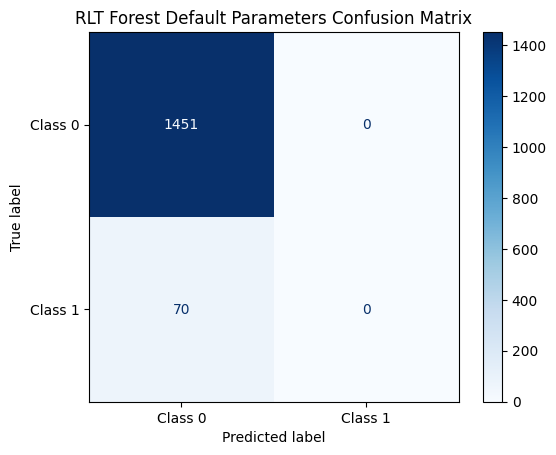

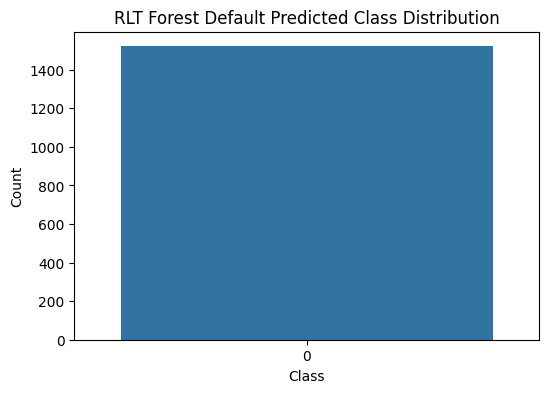

RLT Forest Default Accuracy: 0.9539776462853385
              precision    recall  f1-score   support

           0       0.95      1.00      0.98      1451
           1       0.00      0.00      0.00        70

    accuracy                           0.95      1521
   macro avg       0.48      0.50      0.49      1521
weighted avg       0.91      0.95      0.93      1521



C:\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [7]:
# Train and evaluate RLT Forest with default parameters

# Train model
rlt_forest_default = RLTForest(
    n_estimators=10,
    max_depth=7,
    min_samples=15,
    mute_rate=0.5,
    min_vars=5,
    random_state=42
)
rlt_forest_default.fit(X_train, y_train)
rlt_preds_default = rlt_forest_default.predict(X_test)

# Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

cm_default = confusion_matrix(y_test, rlt_preds_default)
cmd_default = ConfusionMatrixDisplay(cm_default, display_labels=["Class 0", "Class 1"])
cmd_default.plot(cmap='Blues')
plt.title("RLT Forest Default Parameters Confusion Matrix")
plt.show()

# Predicted Class Distribution
plt.figure(figsize=(6,4))
sns.countplot(x=rlt_preds_default)
plt.title('RLT Forest Default Predicted Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

# Print metrics
print("RLT Forest Default Accuracy:", accuracy_score(y_test, rlt_preds_default))
print(classification_report(y_test, rlt_preds_default))


C:\Users\lenovo\AppData\Local\Temp\ipykernel_3312\2576950366.py:52: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if x_row[self.split_feature] <= self.split_value:


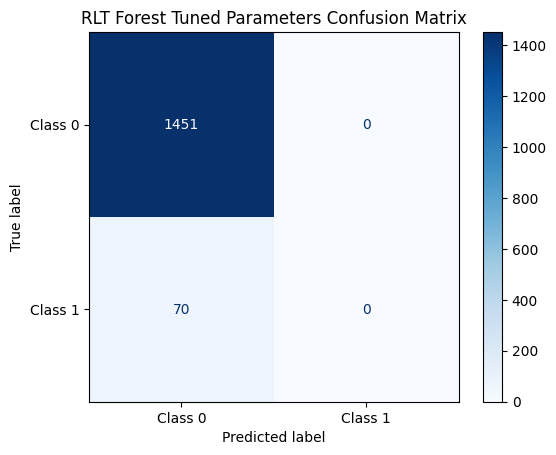

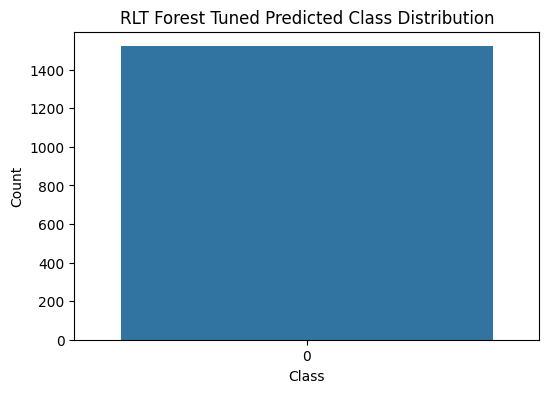

RLT Forest Tuned Accuracy: 0.9539776462853385
              precision    recall  f1-score   support

           0       0.95      1.00      0.98      1451
           1       0.00      0.00      0.00        70

    accuracy                           0.95      1521
   macro avg       0.48      0.50      0.49      1521
weighted avg       0.91      0.95      0.93      1521



C:\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [8]:
# Train and evaluate RLT Forest with tuned parameters

rlt_forest_tuned = RLTForest(
    n_estimators=30,    # more trees for stability
    max_depth=12,       # deeper trees
    min_samples=5,      # allow splits with fewer samples
    mute_rate=0.2,      # less aggressive muting
    min_vars=5,
    random_state=42
)
rlt_forest_tuned.fit(X_train, y_train)
rlt_preds_tuned = rlt_forest_tuned.predict(X_test)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

cm_tuned = confusion_matrix(y_test, rlt_preds_tuned)
cmd_tuned = ConfusionMatrixDisplay(cm_tuned, display_labels=["Class 0", "Class 1"])
cmd_tuned.plot(cmap='Blues')
plt.title("RLT Forest Tuned Parameters Confusion Matrix")
plt.show()

plt.figure(figsize=(6,4))
sns.countplot(x=rlt_preds_tuned)
plt.title('RLT Forest Tuned Predicted Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

print("RLT Forest Tuned Accuracy:", accuracy_score(y_test, rlt_preds_tuned))
print(classification_report(y_test, rlt_preds_tuned))
